In [995]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [996]:
df = pd.read_csv("insurance.csv")

# EDA


In [997]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [998]:
df.shape

(1338, 7)

In [999]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [1000]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [1001]:
df[df.duplicated()]

,age,sex,bmi,children,smoker,region,charges
581,19,male,30.59,0,no,northwest,1639.5631


In [1002]:
df["age"].min()

np.int64(18)

In [1003]:
df.describe(include='object')

,sex,smoker,region
count,1338,1338,1338
unique,2,2,4
top,male,no,southeast
freq,676,1064,364


In [1004]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [1005]:
df["region"].value_counts()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

In [1006]:
df.describe(include="object")

,sex,smoker,region
count,1338,1338,1338
unique,2,2,4
top,male,no,southeast
freq,676,1064,364


In [1007]:
categorical_columns = ['sex', 'smoker', 'region']

for col in categorical_columns:
    print(f"{col}: {df[col].unique()}")
    

sex: <ArrowStringArray>
['female', 'male']
Length: 2, dtype: str
smoker: <ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str
region: <ArrowStringArray>
['southwest', 'southeast', 'northwest', 'northeast']
Length: 4, dtype: str


In [1008]:
for col in categorical_columns:
    print(df[col].value_counts())

sex
male      676
female    662
Name: count, dtype: int64
smoker
no     1064
yes     274
Name: count, dtype: int64
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


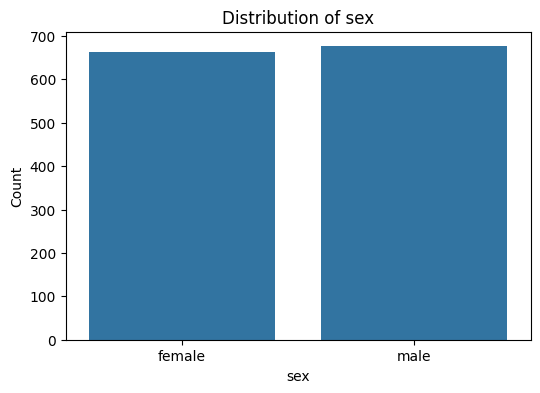

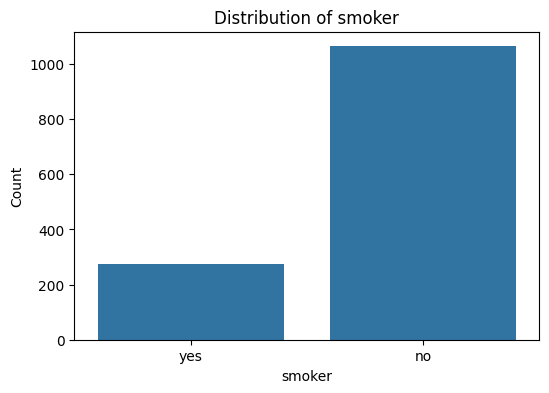

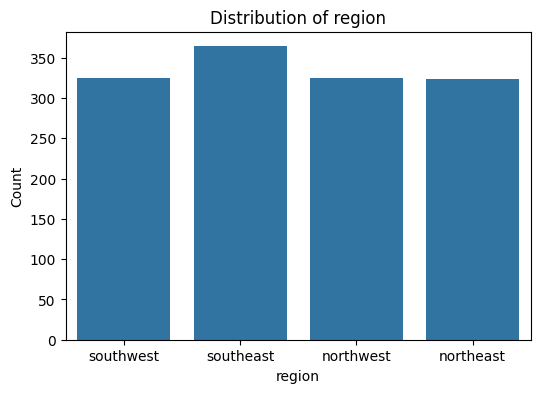

In [1009]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in categorical_columns:
    plt.figure(figsize=(6, 4))

    sns.countplot(data=df, x=col)

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")

    plt.show()

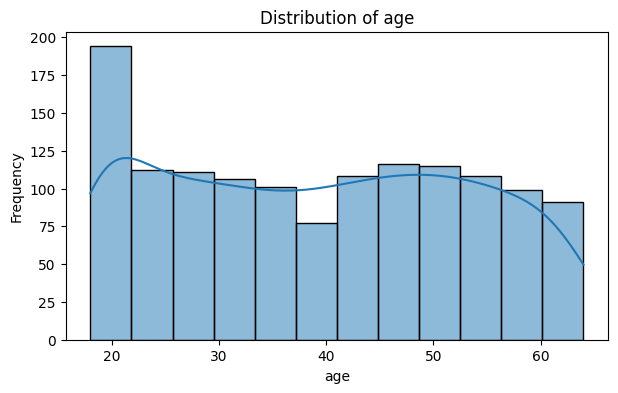

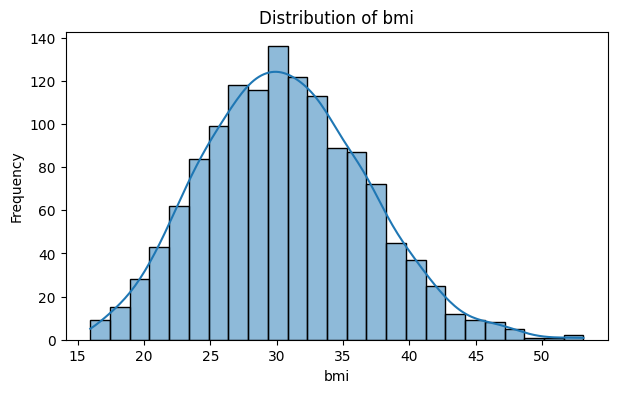

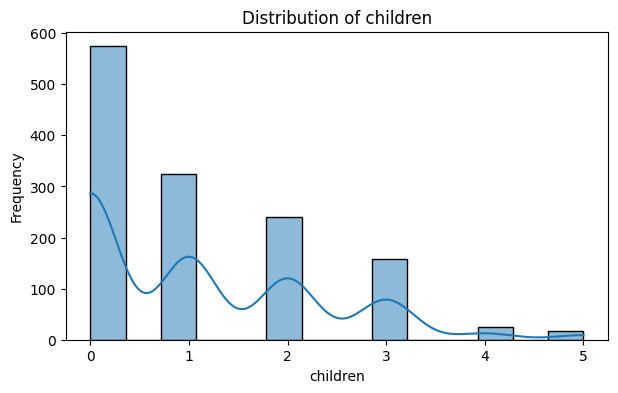

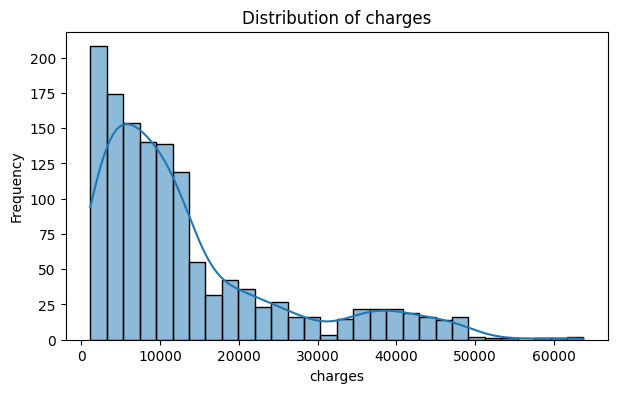

In [1010]:
numerical_columns = ['age', 'bmi', 'children', 'charges']
for col in numerical_columns:
    plt.figure(figsize=(7, 4))

    sns.histplot(data=df, x=col, kde=True)

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.show()

In [1011]:
df["bmi"].describe()

count    1338.000000
mean       30.663397
std         6.098187
min        15.960000
25%        26.296250
50%        30.400000
75%        34.693750
max        53.130000
Name: bmi, dtype: float64

In [1012]:
df[numerical_columns].skew()

age         0.055673
bmi         0.284047
children    0.938380
charges     1.515880
dtype: float64

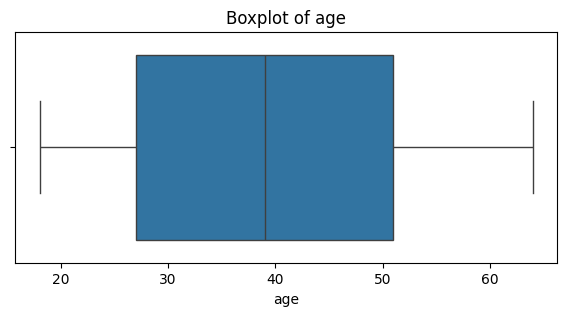

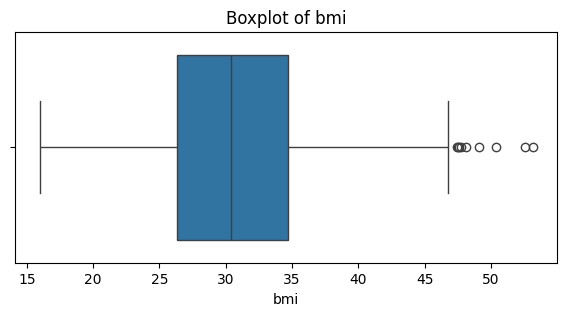

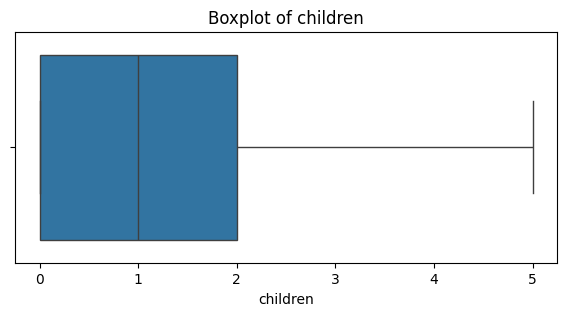

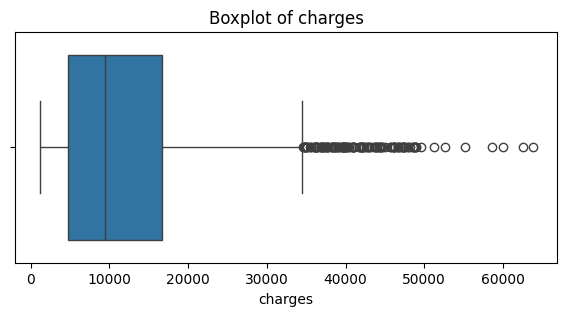

In [1013]:
for col in numerical_columns:
    plt.figure(figsize=(7, 3))

    sns.boxplot(data=df, x=col)

    plt.title(f"Boxplot of {col}")

    plt.show()

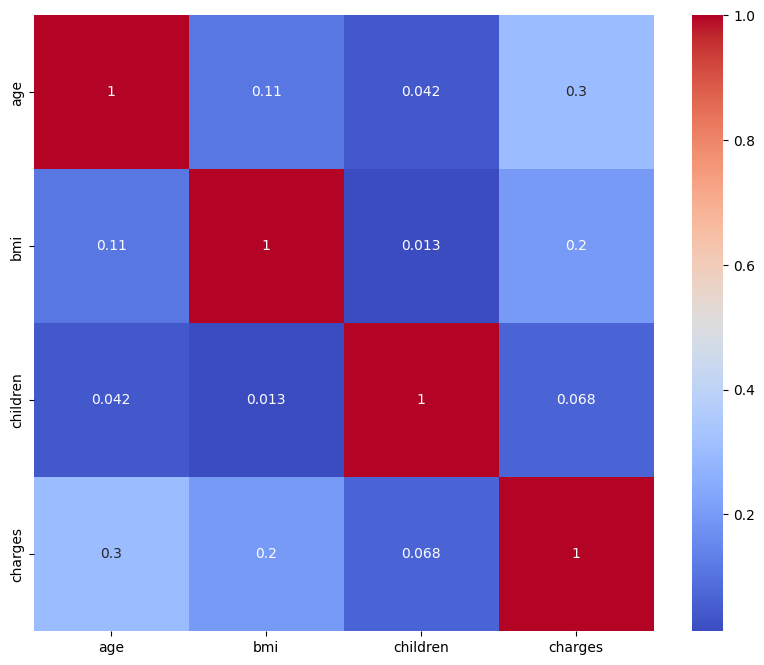

In [1014]:
# heatmap realtionship between numerical columns

plt.figure(figsize=(10, 8))

sns.heatmap(df[numerical_columns].corr(), annot=True, cmap="coolwarm")

plt.show()

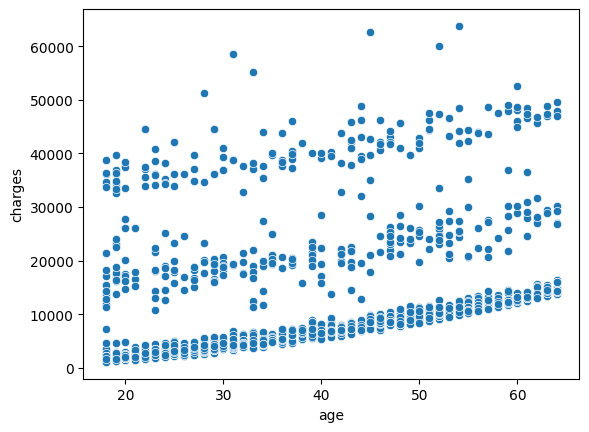

In [1015]:
sns.scatterplot(data=df, x='age', y='charges')
plt.show()

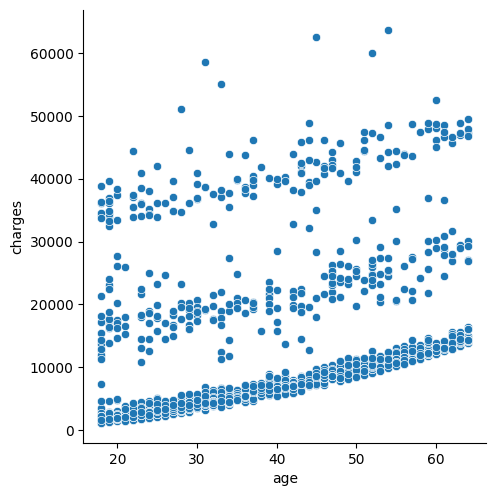

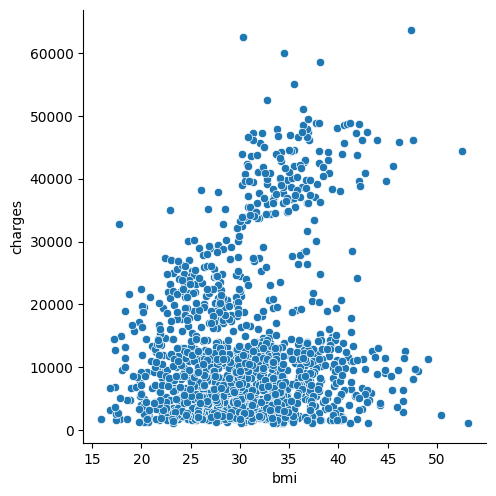

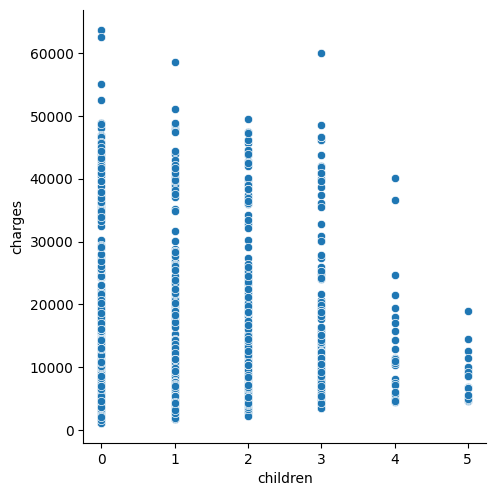

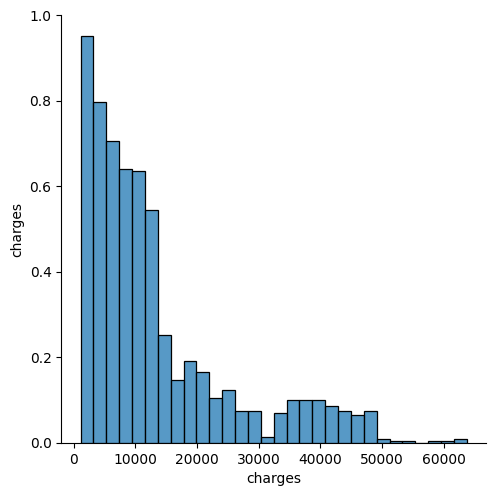

In [1016]:
# pair plot
for col in numerical_columns:
    sns.pairplot(data=df, x_vars=col, y_vars='charges', height=5)
    plt.show()

## Data Cleaning

In [1017]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [1018]:
(df.isnull().mean()*100).round(2)

age         0.0
sex         0.0
bmi         0.0
children    0.0
smoker      0.0
region      0.0
charges     0.0
dtype: float64

In [1019]:
# replacing the bmi values with median
# df["bmi"] = df["bmi"].fillna(df["bmi"].median())
# df["bmi"] = df["bmi"].fillna(df["bmi"].mean())

In [1020]:
# df['smoker'] = df['smoker'].fillna(df['smoker'].mode()[0])

In [1021]:
df.duplicated().sum()

np.int64(1)

In [1022]:
df[df.duplicated()]

,age,sex,bmi,children,smoker,region,charges
581,19,male,30.59,0,no,northwest,1639.5631


In [1023]:
df.drop_duplicates(inplace=True)

In [1024]:
df.duplicated().sum()

np.int64(0)

In [1025]:
# take out the names of the features
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

In [1026]:
# find the unique value of the columns

for col in numerical_columns:
    print(df[col].unique())

[19 18 28 33 32 31 46 37 60 25 62 23 56 27 52 30 34 59 63 55 22 26 35 24
 41 38 36 21 48 40 58 53 43 64 20 61 44 57 29 45 54 49 47 51 42 50 39]
[27.9   33.77  33.    22.705 28.88  25.74  33.44  27.74  29.83  25.84
 26.22  26.29  34.4   39.82  42.13  24.6   30.78  23.845 40.3   35.3
 36.005 32.4   34.1   31.92  28.025 27.72  23.085 32.775 17.385 36.3
 35.6   26.315 28.6   28.31  36.4   20.425 32.965 20.8   36.67  39.9
 26.6   36.63  21.78  30.8   37.05  37.3   38.665 34.77  24.53  35.2
 35.625 33.63  28.    34.43  28.69  36.955 31.825 31.68  22.88  37.335
 27.36  33.66  24.7   25.935 22.42  28.9   39.1   36.19  23.98  24.75
 28.5   28.1   32.01  27.4   34.01  29.59  35.53  39.805 26.885 38.285
 37.62  41.23  34.8   22.895 31.16  27.2   26.98  39.49  24.795 31.3
 38.28  19.95  19.3   31.6   25.46  30.115 29.92  27.5   28.4   30.875
 27.94  35.09  29.7   35.72  32.205 28.595 49.06  27.17  23.37  37.1
 23.75  28.975 31.35  33.915 28.785 28.3   37.4   17.765 34.7   26.505
 22.04  35.9   25.

In [1027]:
df[(df["age"] >=25) & (df["age"] <=39)][["age", "sex", "bmi", "charges"]].describe()

,age,bmi,charges
count,396.000000,396.000000,396.000000
mean,31.810606,30.100227,10961.646569
std,4.327362,6.178078,11489.811124
min,25.000000,16.815000,2137.653600
25%,28.000000,25.900000,4256.455512
50%,32.000000,29.700000,5413.001925
75%,36.000000,34.105000,16459.815787
max,39.000000,47.600000,58571.074480


In [1028]:
# Handle Incorrect or Invalid Values

df[(df["age"]<0) | (df["bmi"] < 0) | (df["charges"] < 0) | (df["children"] < 0)]

,age,sex,bmi,children,smoker,region,charges


In [1029]:
df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


In [1030]:
# detecting the outliers
q1 = 27.000000
q3 = 51.000000
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outlier = df[
    (df['charges'] < lower_bound) |
    (df['charges'] > upper_bound)
]



In [1031]:
# Z-score method:
from scipy.stats import zscore

z_scores = zscore(df['charges'])


outliers = df[abs(z_scores) > 3]

outliers.describe()

,age,bmi,children,charges
count,7.000000,7.000000,7.000000,7.000000
mean,43.285714,36.440000,0.714286,57696.652167
std,12.671678,5.445911,1.112697,4863.802290
min,28.000000,30.360000,0.000000,51194.559140
25%,32.000000,33.642500,0.000000,53863.115740
50%,45.000000,35.530000,0.000000,58571.074480
75%,53.000000,37.247500,1.000000,61307.136030
max,60.000000,47.410000,3.000000,63770.428010


## Data Processing

In [1032]:
X = df.drop("charges", axis=1)
y = df["charges"]

In [1033]:
from sklearn.preprocessing import LabelEncoder

labelEncoder = LabelEncoder()
# apply labelencoder on the sex column

X["sex"] = labelEncoder.fit_transform(X["sex"])
X["smoker"] = labelEncoder.fit_transform(X["smoker"])

In [1034]:
# 1 -> male
# 0 -> female
X["sex"].value_counts()
X["smoker"].value_counts()

smoker
0    1063
1     274
Name: count, dtype: int64

In [1035]:
X

,age,sex,bmi,children,smoker,region
0,19,0,27.900,0,1,southwest
1,18,1,33.770,1,0,southeast
2,28,1,33.000,3,0,southeast
3,33,1,22.705,0,0,northwest
4,32,1,28.880,0,0,northwest
...,...,...,...,...,...,...
1333,50,1,30.970,3,0,northwest
1334,18,0,31.920,0,0,northeast
1335,18,0,36.850,0,0,southeast
1336,21,0,25.800,0,0,southwest


In [1036]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False)

encoded_data = encoder.fit_transform(df[['region']])


In [1037]:
# get the features name from the encoder
encoder.get_feature_names_out(['region'])

array(['region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest'], dtype=object)

In [1038]:
encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(['region']),
    index=df.index
)

In [1039]:
encoded_df

,region_northeast,region_northwest,region_southeast,region_southwest
0,0.0,0.0,0.0,1.0
1,0.0,0.0,1.0,0.0
2,0.0,0.0,1.0,0.0
3,0.0,1.0,0.0,0.0
4,0.0,1.0,0.0,0.0
...,...,...,...,...
1333,0.0,1.0,0.0,0.0
1334,1.0,0.0,0.0,0.0
1335,0.0,0.0,1.0,0.0
1336,0.0,0.0,0.0,1.0


In [1040]:
X = X.drop(columns=['region'])

In [1041]:
X = pd.concat([X, encoded_df], axis=1)

In [1042]:
X 

,age,sex,bmi,children,smoker,region_northeast,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,0.0,0.0,0.0,1.0
1,18,1,33.770,1,0,0.0,0.0,1.0,0.0
2,28,1,33.000,3,0,0.0,0.0,1.0,0.0
3,33,1,22.705,0,0,0.0,1.0,0.0,0.0
4,32,1,28.880,0,0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...
1333,50,1,30.970,3,0,0.0,1.0,0.0,0.0
1334,18,0,31.920,0,0,1.0,0.0,0.0,0.0
1335,18,0,36.850,0,0,0.0,0.0,1.0,0.0
1336,21,0,25.800,0,0,0.0,0.0,0.0,1.0


In [1043]:
X["bmi_category"] = pd.cut(
    X["bmi"],
    bins=[0, 18.5, 24.9, 29.9, float("inf")],
    labels=["underweight", "healthy", "overweight", "obese"]
)

In [1044]:
encoded_data = encoder.fit_transform(X[['bmi_category']])
encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(['bmi_category']),
    index=X.index
)

In [1045]:
encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(['bmi_category']),
    index=X.index
)

In [1046]:
X = X.drop(columns=['bmi_category'])

In [1047]:
X = pd.concat([X, encoded_df], axis=1)

In [1048]:
X

,age,sex,bmi,children,smoker,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_healthy,bmi_category_obese,bmi_category_overweight,bmi_category_underweight
0,19,0,27.900,0,1,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,18,1,33.770,1,0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,28,1,33.000,3,0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3,33,1,22.705,0,0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
4,32,1,28.880,0,0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,1,30.970,3,0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
1334,18,0,31.920,0,0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1335,18,0,36.850,0,0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1336,21,0,25.800,0,0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [1049]:
from sklearn.preprocessing import StandardScaler

cols = ["age", "bmi", "children"]

scaler = StandardScaler()

X[cols] = scaler.fit_transform(X[cols])

In [1050]:
X

,age,sex,bmi,children,smoker,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_healthy,bmi_category_obese,bmi_category_overweight,bmi_category_underweight
0,-1.440418,0,-0.453160,-0.909234,1,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,-1.511647,1,0.509422,-0.079442,0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,-0.799350,1,0.383155,1.580143,0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3,-0.443201,1,-1.305052,-0.909234,0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
4,-0.514431,1,-0.292456,-0.909234,0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,0.767704,1,0.050269,1.580143,0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
1334,-1.511647,0,0.206053,-0.909234,0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1335,-1.511647,0,1.014490,-0.909234,0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1336,-1.297958,0,-0.797524,-0.909234,0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [1051]:
XY = pd.concat([X, y], axis=1)

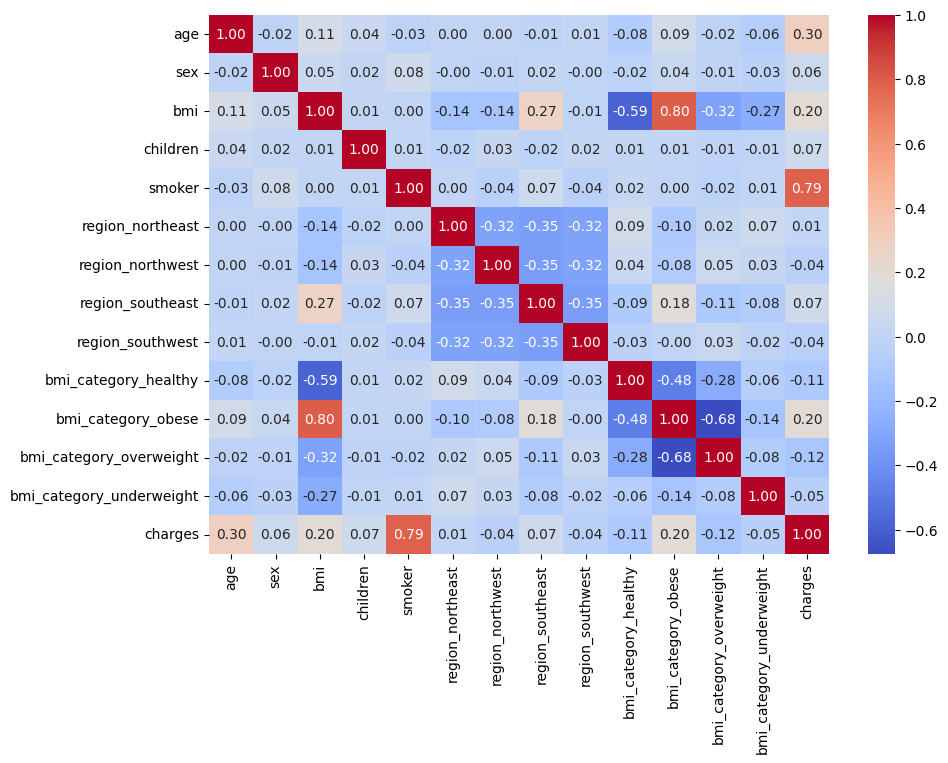

In [1052]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation = XY.corr(numeric_only=True)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.show()

In [1053]:
X.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region_northeast',
       'region_northwest', 'region_southeast', 'region_southwest',
       'bmi_category_healthy', 'bmi_category_obese', 'bmi_category_overweight',
       'bmi_category_underweight'],
      dtype='str')

## Pearson correlation (pearsonr)

In [1054]:
selected_features = ['age', 'sex', 'bmi', 'children', 'smoker', 'region_northeast',
       'region_northwest', 'region_southeast', 'region_southwest',
       'bmi_category_healthy', 'bmi_category_obese', 'bmi_category_overweight',
       'bmi_category_underweight']


In [1055]:
from scipy.stats import pearsonr

correlation = {
    feature: pearsonr(X[feature], df["charges"])[0] for feature in selected_features
}


In [1056]:
correlation

{'age': np.float64(0.29830821250978634),
 'sex': np.float64(0.058044495790312865),
 'bmi': np.float64(0.19840083122624935),
 'children': np.float64(0.06738935083963248),
 'smoker': np.float64(0.7872343672800317),
 'region_northeast': np.float64(0.005945323272979339),
 'region_northwest': np.float64(-0.03869463262101644),
 'region_southeast': np.float64(0.07357792870627781),
 'region_southwest': np.float64(-0.04363736849776149),
 'bmi_category_healthy': np.float64(-0.10565491184703031),
 'bmi_category_obese': np.float64(0.19765936538425974),
 'bmi_category_overweight': np.float64(-0.11827940434445601),
 'bmi_category_underweight': np.float64(-0.048224770768365136)}

In [1057]:
correlation_df = pd.DataFrame.from_dict(correlation, orient='index', columns=['correlation'])

In [1058]:
correlation_df = pd.DataFrame.from_dict(
    correlation,
    orient='index',
    columns=['correlation']
)

correlation_df.index.name = 'Features'

correlation_df = correlation_df.reset_index()

print(correlation_df)

                    Features  correlation
0                        age     0.298308
1                        sex     0.058044
2                        bmi     0.198401
3                   children     0.067389
4                     smoker     0.787234
5           region_northeast     0.005945
6           region_northwest    -0.038695
7           region_southeast     0.073578
8           region_southwest    -0.043637
9       bmi_category_healthy    -0.105655
10        bmi_category_obese     0.197659
11   bmi_category_overweight    -0.118279
12  bmi_category_underweight    -0.048225


In [1059]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [1060]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import BaggingRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

models = {
    'Linear Regression': LinearRegression(),
    'K-Nearest Neighbors': KNeighborsRegressor(),
    'Decision Tree': DecisionTreeRegressor(max_depth=5, random_state=42),
    'Random Forest': RandomForestRegressor( n_estimators=10, random_state=42),
    'Support Vector Regression': SVR( kernel='rbf', C=1, epsilon=0.1),
    'Gradient Boosting': GradientBoostingRegressor(),
    'Bagging': BaggingRegressor(n_estimators=10, random_state=42)
}


In [1061]:
def evaluate_model(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)

    return mse, r2, mae

In [1062]:
results = {}

for name, model in models.items():
    mse, r2, mae = evaluate_model(model, X_train, y_train, X_test, y_test)
    results[name] = {'mse': mse, 'r2': r2, 'mae': mae}

In [1063]:
results_df = pd.DataFrame.from_dict(results, orient='index', columns=['mse', 'r2', 'mae'])

In [1064]:
results_df

,mse,r2,mae
Linear Regression,3.625056e+07,0.802725,4340.612853
K-Nearest Neighbors,7.877985e+07,0.571280,5210.636419
Decision Tree,1.954847e+07,0.893617,2603.143531
Random Forest,2.207557e+07,0.879865,2531.848398
Support Vector Regression,2.082686e+08,-0.133397,9267.277659
Gradient Boosting,1.805629e+07,0.901738,2524.180557
Bagging,2.185175e+07,0.881083,2502.607259


In [1073]:
results_df[
    results_df["r2"] >= 0.90
][["mse", "r2", "mae"]]

,mse,r2,mae
Gradient Boosting,1.805629e+07,0.901738,2524.180557
